# Bab 7 — How to picture neural networks: in your head and on paper

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 7, halaman cetak 133–143 (PDF 154–164, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Menggambar jaringan dengan dimensi, menerjemahkan diagram ke kode, dan menjelaskan korelasi lokal/global.

## Ringkasan

Bab ini mengompresi cara berpikir tentang jaringan: dari garis individual menjadi vektor, matriks, dan jalur korelasi. Gambar, aljabar, dan Python adalah tiga representasi dari operasi yang sama.

## Konsep, intuisi, dan notasi

$l_0\in\mathbb R^{1\times3}$, $W_0\in\mathbb R^{3\times4}$, $l_1=\operatorname{ReLU}(l_0W_0)\in\mathbb R^{1\times4}$, $W_1\in\mathbb R^{4\times1}$, dan $l_2=l_1W_1\in\mathbb R^{1\times1}$.

**Correlation summarization**: jaringan mencari relasi input-target, termasuk relasi yang dibentuk oleh hidden layer. Lokal berarti satu matriks menyesuaikan hubungan lapisan masuk dan keluarnya. Global berarti backprop meneruskan kebutuhan output akhir ke lapisan lebih awal. Ini adalah ringkasan optimasi, bukan klaim sebab-akibat.

Bentuk matriks dapat disimpulkan dari jumlah unit yang dihubungkan. Gambar perlu menunjukkan arah aliran, ukuran, fungsi aktivasi, serta lokasi bobot bersama. Menghapus garis per-bobot mengurangi beban visual tanpa membuang informasi arsitektur yang diperlukan.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b07-visual"></a>

## Dari gambar rinci ke matriks dan vektor

**Sumber:** cetak 134–139; PDF 155–160.

**Reproduksi konseptual.** Mulai dari neuron individual, ringkas satu kelompok menjadi vektor aktivasi dan kelompok koneksi menjadi matriks. Matriks menyimpan transformasi yang dipelajari; vektor menyimpan keadaan yang bergantung pada input. Arsitektur menentukan jalur informasi sehingga pola yang relevan lebih mudah ditemukan.

**Ilustrasi tambahan.** Diagram berikut memakai dimensi buku. Angka bobot akan dibangkitkan untuk memeriksa bentuk, bukan menyalin angka ilustratif pada gambar cetak.

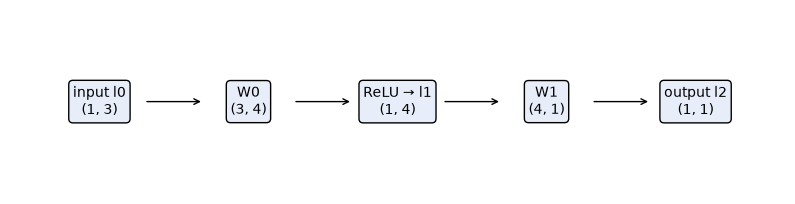

In [2]:
fig,ax=plt.subplots(figsize=(10,2.4))
labels=['input l0\n(1, 3)','W0\n(3, 4)','ReLU → l1\n(1, 4)','W1\n(4, 1)','output l2\n(1, 1)']
for i,label in enumerate(labels):
    ax.text(i,0,label,ha='center',va='center',bbox=dict(boxstyle='round',fc='#e8eef9'))
    if i<4: ax.annotate('',xy=(i+.7,0),xytext=(i+.3,0),arrowprops=dict(arrowstyle='->'))
ax.set(xlim=(-.6,4.6),ylim=(-.6,.6)); ax.axis('off'); plt.show()

<a id="b07-algebra"></a>

## Letters, linking variables, dan everything side by side

**Sumber:** cetak 140–143; PDF 161–164.

Huruf `l` menyatakan layer dan `W` bobot. Menuliskan $l_2=\operatorname{ReLU}(l_0W_0)W_1$ sekaligus menyatakan urutan operasi. **Reproduksi ekspresi buku** berikut dicocokkan dengan versi bertahap. Bobot acak adalah **tambahan**; tidak ada pelatihan baru pada bab ini.

Alat visual bermanfaat untuk debugging: jika output punya ukuran salah, telusuri dimensi pada panah. Jika semua ukuran benar tetapi model buruk, periksa apakah arsitektur mempertahankan sinyal yang diperlukan. Gambar yang rapi tidak membuktikan model sudah belajar.

In [3]:
l0=np.array([[1.,0.,1.]])
W0=np.random.uniform(-1,1,(3,4)); W1=np.random.uniform(-1,1,(4,1))
l1=np.maximum(0,l0@W0); l2=l1@W1
compact=np.maximum(0,l0.dot(W0)).dot(W1)
np.testing.assert_allclose(l2,compact)
for name,a in [('l0',l0),('W0',W0),('l1',l1),('W1',W1),('l2',l2)]: print(name,a.shape,a)
record(expressions_equal=True,parameter_count=int(W0.size+W1.size))

l0 (1, 3) [[1. 0. 1.]]
W0 (3, 4) [[-0.165956  0.440649 -0.999771 -0.395335]
 [-0.706488 -0.815323 -0.62748  -0.308879]
 [-0.206465  0.077633 -0.161611  0.370439]]
l1 (1, 4) [[0.       0.518282 0.       0.      ]]
W1 (4, 1) [[-0.591096]
 [ 0.756235]
 [-0.945225]
 [ 0.340935]]
l2 (1, 1) [[0.391943]]


## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:50:18.707446+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

Ekspresi bertahap dan ringkas sama. Jumlah parameter 16 sesuai 3×4 + 4×1 tanpa bias. Prediksi berasal dari bobot demonstrasi acak.

## Kesimpulan dan pembahasan pertanyaan

Diagram dan kode memuat operasi yang sama. Jaringan contoh memiliki 16 bobot tanpa bias; jumlah ini berasal dari 3×4 + 4×1. Angka prediksi adalah hasil bobot demonstrasi dan tidak bermakna sebagai model terlatih.

**Apa beda layer dan weights?** Layer adalah aktivasi yang berubah menurut input; weights adalah parameter transformasinya.

**Apa yang dapat dihilangkan dari diagram?** Garis per-bobot, selama dimensi dan konektivitas tetap jelas.

**Apakah korelasi menunjukkan sebab-akibat?** Tidak; tujuan supervised learning hanya menyesuaikan prediksi terhadap data yang tersedia.

In [4]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"expressions_equal": true, "parameter_count": 16}
